# code_172 · Storage constraints and Gymnasium-style episode semantics

**Book:** section 32.6. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_32_GUIDE.md), [execution evidence](../CHAPTER_32_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_172).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or operational controllers. Rewards, transitions, observation boundaries and independent assessment are defined below. Simulated rewards do not establish field safety or causal identification from arbitrary logs.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=5372;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 5372


<a id="bounded-storage-stress-tests"></a>
 ## Stress a controller without hiding physical failures behind clipping
 This original environment follows reset→(observation,info) and step→(observation,reward,terminated,truncated,info). It does not import Gymnasium, claim native Env/checker compliance or require an added package. Storage evolves without physical clipping. A bound violation terminates the task; day 24 also naturally terminates, with the remaining clock observed. An external shorter limit truncates a continuing portion of the day. A proposed price-based controller charges at night and discharges at evening peak. Compare no shield, a nominal-efficiency projection, and a robust projection with zero-action fallback on dropped policy sensors. The shield separately receives a trusted storage measurement: its availability is a strong declared system assumption. Robust bounds assume efficiency in[0.7,1.0]; nominal bounds assume 0.92. Test normal days,25%sensor dropout, shifted demand and actual efficiency 0.75. A peak-grid target 1.25 can remain unmet even while storage stays safe. Episode costs and completion fractions expose premature termination rather than rewarding an early crash.


,scenario,controller,episodes,storage_failures,mean_observed_energy_cost,completed_fraction,served_step_fraction,grid_exceedance_fraction_of_observed_steps,shield_overrides,sensor_fallbacks
0,Normal,Unshielded,40,40,0.400667,0.0,0.083333,0.962500,0,0
1,Normal,Nominal shield,40,0,4.273438,1.0,1.000000,0.071875,320,0
2,Normal,Robust + fallback,40,0,4.275407,1.0,1.000000,0.066667,360,0
3,Sensor dropout,Unshielded,40,40,0.400667,0.0,0.083333,0.962500,0,0
4,Sensor dropout,Nominal shield,40,0,4.273438,1.0,1.000000,0.071875,320,0
5,Sensor dropout,Robust + fallback,40,0,4.293144,1.0,1.000000,0.062500,257,222
6,Demand shift,Unshielded,40,40,0.580667,0.0,0.083333,1.000000,0,0
7,Demand shift,Nominal shield,40,0,7.333438,1.0,1.000000,0.889583,320,0
8,Demand shift,Robust + fallback,40,0,7.335407,1.0,1.000000,0.890625,360,0
9,Efficiency shift,Unshielded,40,40,0.600662,0.0,0.125000,0.966667,0,0


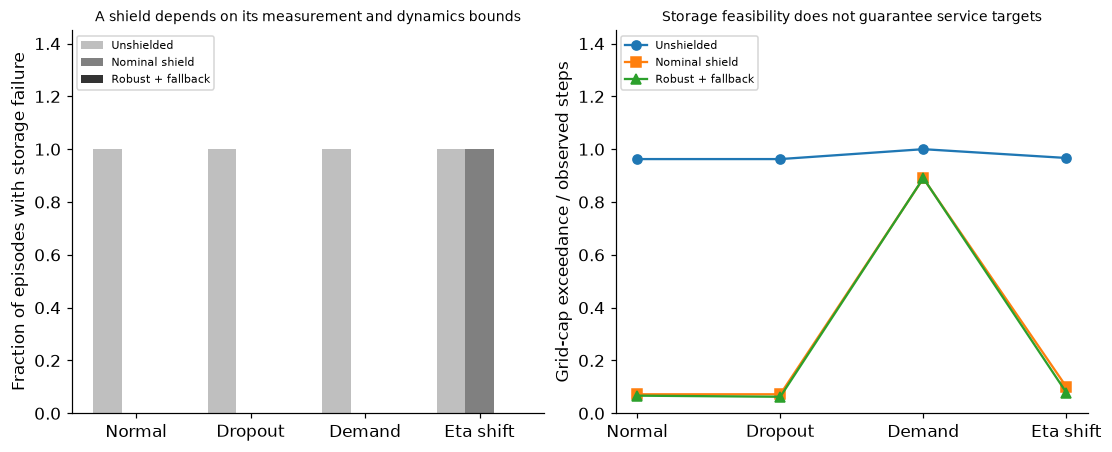

In [2]:
class EnergyEnv:
    def __init__(self,seed,dropout=0.,shift=0.,efficiency=.92,external_limit=24):self.seed=seed;self.dropout=dropout;self.shift=shift;self.eta=efficiency;self.limit=external_limit
    def observation(self):
        measured=np.nan if self.gr.random()<self.dropout else self.s
        return np.array([measured,self.demand[self.t],(24-self.t)/24])
    def reset(self):
        self.gr=np.random.default_rng(self.seed);self.t=0;self.s=.5;self.demand=np.maximum(.1,.8+.25*np.sin(2*np.pi*(np.arange(25)-7)/24)**2+self.gr.normal(0,.05,25)+self.shift);self.ended=False;return self.observation(),{'trusted_storage':self.s}
    def step(self,action):
        assert not self.ended and np.isfinite(action) and abs(action)<=.3+1e-12
        t=self.t;grid=max(0,self.demand[t]+action);self.s+=self.eta*action if action>=0 else action/self.eta;self.t+=1;violation=bool(self.s< -1e-10 or self.s>1+1e-10);terminated=bool(violation or self.t>=24);truncated=bool(self.t>=self.limit and not terminated);self.ended=terminated or truncated;cost=.15*grid if not 16<=t<21 else .45*grid
        info={'trusted_storage':self.s,'storage_violation':violation,'grid_cap_exceeded':grid>1.25,'energy_cost':cost,'elapsed':self.t,'applied_action':action};return self.observation(),-float(cost),terminated,truncated,info
def proposal(obs,t):return .3 if t<7 else (-.3 if 16<=t<21 else 0.)
def shield(action,s,robust):
    lower=-s*(.7 if robust else .92);upper=(1-s)/(1. if robust else .92);return float(np.clip(action,max(-.3,lower),min(.3,upper)))
scenarios={'Normal':{},'Sensor dropout':{'dropout':.25},'Demand shift':{'shift':.6},'Efficiency shift':{'efficiency':.75}}
rows=[];traces={}
for scenario,kwargs in scenarios.items():
    for mode in ['Unshielded','Nominal shield','Robust + fallback']:
        costs=[];failures=0;steps=0;grid_exceeded=0;overrides=0;fallbacks=0
        for episode in range(40):
            env=EnergyEnv(SEED+episode,**kwargs);obs,info=env.reset();trace=[];total=0.
            while True:
                t=env.t;raw=proposal(obs,t)
                if mode=='Robust + fallback' and np.isnan(obs[0]):raw=0.;fallbacks+=1
                applied=raw if mode=='Unshielded' else shield(raw,info['trusted_storage'],mode=='Robust + fallback');overrides+=int(abs(applied-raw)>1e-12);obs,reward,term,trunc,info=env.step(applied);total-=reward;trace.append((t,info['trusted_storage'],raw,applied));steps+=1;grid_exceeded+=int(info['grid_cap_exceeded'])
                if term or trunc:failures+=int(info['storage_violation']);break
            costs.append(total);traces[(scenario,mode,episode)]=trace
        rows.append({'scenario':scenario,'controller':mode,'episodes':40,'storage_failures':failures,'mean_observed_energy_cost':float(np.mean(costs)),'completed_fraction':float(sum(len(traces[(scenario,mode,i)])==24 for i in range(40))/40),'served_step_fraction':steps/(40*24),'grid_exceedance_fraction_of_observed_steps':grid_exceeded/steps,'shield_overrides':overrides,'sensor_fallbacks':fallbacks})
assert len(rows)==12 and all(r['storage_failures']==0 for r in rows if r['controller']=='Robust + fallback')
RESULTS.update(episodes_per_scenario_controller=40,environment_interface='original Gymnasium-style five-tuple; not native Gymnasium Env',trusted_independent_storage_sensor_assumed=True,robust_efficiency_interval=[.7,1.],grid_cap_target=1.25,stress_metrics=rows)
display(pd.DataFrame(rows));fig,axes=plt.subplots(1,2,figsize=(10,4));labels=list(scenarios);modes=['Unshielded','Nominal shield','Robust + fallback']
for j,mode in enumerate(modes):
    rr=[r for r in rows if r['controller']==mode];axes[0].bar(np.arange(4)+(j-1)*.25,[r['storage_failures']/40 for r in rr],width=.25,color=['.75','.5','.2'][j],label=mode);axes[1].plot(range(4),[r['grid_exceedance_fraction_of_observed_steps'] for r in rr],marker=['o','s','^'][j],label=mode)
for ax in axes:ax.set_xticks(range(4),['Normal','Dropout','Demand','Eta shift'])
axes[0].set(ylabel='Fraction of episodes with storage failure',ylim=(0,1.45),title='A shield depends on its measurement and dynamics bounds');axes[0].legend(fontsize=7,loc='upper left');axes[1].set(ylabel='Grid-cap exceedance / observed steps',title='Storage feasibility does not guarantee service targets',ylim=(0,1.45));axes[1].legend(fontsize=7,loc='upper left');plt.show()


<a id="termination-and-truncation-tests"></a>
 ## Stop interaction on either flag; bootstrap only through truncation
 Reset two identical environments: an eight-step external cutoff returns truncated=True without terminal failure, while the natural 24-hour clock returns terminated=True. Value targets retain the observed final transition, never the reset observation. A known continuation value 5 at discount 0.9 and reward 1 gives 5.5 after external truncation and 1 at a true terminal boundary. Incorrectly combining both flags into one bootstrap mask changes the first target to 1. A finite horizon inherent to the task is terminal; adding time to observations preserves its state description. Physical failure is also terminal. These assertions test interface semantics and declared model bounds, not hardware integration, field reliability or performance outside the efficiency interval.


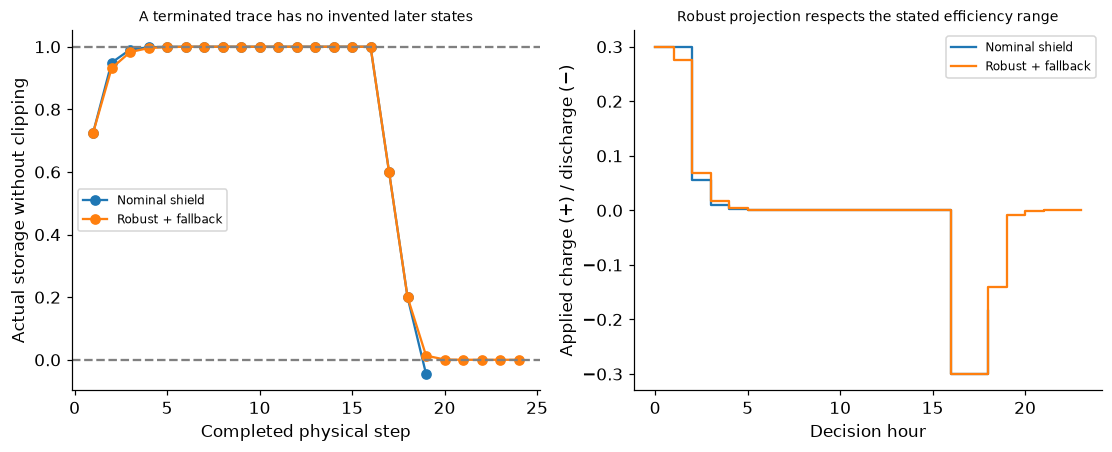

In [3]:
cut=EnergyEnv(SEED,external_limit=8);ob,info=cut.reset()
for k in range(8):ob,reward,term,trunc,info=cut.step(0.)
assert trunc and not term and info['elapsed']==8
natural=EnergyEnv(SEED);ob,info=natural.reset()
for k in range(24):ob,reward,term,trunc,info=natural.step(0.)
assert term and not trunc and info['elapsed']==24
target_truncated=1+.9*5;target_terminal=1.;wrong=1.;assert target_truncated==5.5 and target_terminal==wrong
for eta in [.7,.75,.92,1.]:
    for s in np.linspace(0,1,51):
        for raw in [-.3,0,.3]:
            a=shield(raw,s,True);ns=s+(eta*a if a>=0 else a/eta);assert -1e-12<=ns<=1+1e-12
RESULTS.update(bootstrap_test={'reward':1.,'discount':.9,'next_value':5.,'external_truncation_target':target_truncated,'true_terminal_target':target_terminal,'incorrect_combined_done_target':wrong},robust_projection_grid_cases=4*51*3,finite_horizon_clock_observed=True,physical_failure_terminal=True)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for mode in ['Nominal shield','Robust + fallback']:
    trace=np.array(traces[('Efficiency shift',mode,0)]);axes[0].plot(trace[:,0]+1,trace[:,1],marker='o',label=mode);axes[1].step(trace[:,0],trace[:,3],where='post',label=mode)
axes[0].axhline(0,color='.5',linestyle='--');axes[0].axhline(1,color='.5',linestyle='--');axes[0].set(xlabel='Completed physical step',ylabel='Actual storage without clipping',title='A terminated trace has no invented later states');axes[0].legend(fontsize=8);axes[1].set(xlabel='Decision hour',ylabel='Applied charge (+) / discharge (−)',title='Robust projection respects the stated efficiency range');axes[1].legend(fontsize=8);plt.show()


In [4]:
summary={'example_id':'code_172','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['original five-tuple Gymnasium-style environment with explicit observed clock', 'actual feasible-action shields using trusted independent storage measurement', 'normal dropout demand-shift and efficiency-mismatch stress scenarios', 'nominal versus bounded-uncertainty robust projection and fallback', 'termination versus external truncation bootstrap tests and early-failure accounting'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["original five-tuple Gymnasium-style environment with explicit observed clock", "actual feasible-action shields using trusted independent storage measurement", "normal dropout demand-shift and efficiency-mismatch stress scenarios", "nominal versus bounded-uncertainty robust projection and fallback", "termination versus external truncation bootstrap tests and early-failure accounting"], "elapsed_seconds": 0.567, "example_id": "code_172", "hardware": "Darwin arm64 CPU", "results": {"bootstrap_test": {"discount": 0.9, "external_truncation_target": 5.5, "incorrect_combined_done_target": 1.0, "next_value": 5.0, "reward": 1.0, "true_terminal_target": 1.0}, "environment_interface": "original Gymnasium-style five-tuple; not native Gymnasium Env", "episodes_per_scenario_controller": 40, "finite_horizon_clock_observed": true, "grid_cap_target": 1.25, "physical_failure_terminal": true, "robust_efficiency_interval": [0.7, 1.0], "robust_projection_g